# 🧹 Data collection and preprocessing: Cambodian food places

Notebook **1 of 2** of the Information Retrieval project. It collects food places in **Phnom Penh** from several sources,
cleans and merges them, checks the quality, and writes **one clean file: `data/restaurants.csv`**.
The second notebook, **`food_search.ipynb`**, starts from that file (indexing, search, evaluation, RAG chatbot, Telegram bot).

| Step | What happens | Why |
|---|---|---|
| 1 | **Collect**: OpenStreetMap, Overture Maps (open data with Facebook page links), your Google Sheet, Telegram seller channels | every source has different strengths |
| 2 | **Merge and de-duplicate** | the same place can appear in several sources, or twice in one |
| 3 | **Clean** | Khmer Unicode, spaces, riel → USD, opening hours, impossible values |
| 4 | **Search text** | how Khmer and English text is split into searchable pieces, and spelling variants of dishes |
| 5 | **Quality report** | what the data can and cannot answer (for example: how many places have a price) |
| 6 | **Save** | `data/restaurants.csv` for `food_search.ipynb` |

**How to run (VS Code on a Mac):** select the kernel **venv (food-search)** and *Run All*. Sources you have not set up
(Google Sheet, Telegram channels) are skipped with a message; they never stop the notebook.
Run this notebook again whenever you add places to the Google Sheet or channels to `data/telegram_channels.csv`, then
re-run `food_search.ipynb`.

## 0. Setup

**What:** find the project folder, install packages, import libraries, load settings and secrets.

**Why:** everything later depends on it. The paths are relative to the project root (the folder that contains
this notebook), so the project works on any computer. On Google Colab the same cells adapt automatically.

> ⚠️ **Secrets:** never paste API keys or tokens into this notebook, and never commit `.env`.
> Keys live only in `.env` (VS Code / local) or in *Colab → Secrets*. The notebook prints only *set* / *missing*.

In [1]:
# Where are we running? VS Code / local Jupyter is the default, Colab is supported too.
import os, sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    ROOT = Path.cwd() / "food-search"      # /content/food-search on Colab
    ROOT.mkdir(exist_ok=True)
    os.chdir(ROOT)
else:
    ROOT = Path.cwd()                      # VS Code starts the kernel in the notebook's folder
    if not (ROOT / "data_preprocessing.ipynb").exists():
        print("⚠️ data_preprocessing.ipynb not found in the working folder: open the project folder in VS Code.")
print("Running in Colab:", IN_COLAB)
print("Project root:", ROOT.name)

# Create .env.example and .gitignore once (never overwrite your own files)
ENV_EXAMPLE = """# Copy this file to .env and fill in your own values. Never commit .env!
TELEGRAM_TOKEN=
GEMINI_API_KEY=
GEMINI_MODEL=
OLLAMA_MODEL=
OLLAMA_HOST=http://localhost:11434
LLM_PROVIDER=gemini
EMBED_MODEL=paraphrase-multilingual-MiniLM-L12-v2
ADMIN_IDS=
# Optional: Ollama cloud instead of a local Ollama (set OLLAMA_HOST=https://ollama.com and an OLLAMA_MODEL from its list)
OLLAMA_API_KEY=
# Optional: Google Sheets shared as "Anyone with the link: Viewer" (paste the normal sheet link)
SHEET_CSV_URL=
SHEET_QUERIES_URL=
# Optional: how to read seller channels. preview = public web pages, no login (default); api = Telegram API + login
TG_MODE=preview
# Only for TG_MODE=api (https://my.telegram.org -> API development tools)
TG_API_ID=
TG_API_HASH=
"""
GITIGNORE = ".env\nvenv/\nchroma_db/\nexport/\n__pycache__/\n.ipynb_checkpoints/\n*.session\n"
for name, content in {".env.example": ENV_EXAMPLE, ".gitignore": GITIGNORE}.items():
    path = ROOT / name
    if path.exists():
        print(f"{name} already exists (kept)")
    else:
        path.write_text(content, encoding="utf-8")
        print(f"created {name}")

Running in Colab: False
Project root: food-search
.env.example already exists (kept)
.gitignore already exists (kept)


In [2]:
# Install into the *active kernel's* environment (quiet; fast if already installed)
%pip install -q requests pandas numpy matplotlib python-dotenv telethon duckdb rapidfuzz scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [3]:
import io, re, json, math, html, time, random, logging, asyncio, shutil, unicodedata, warnings
from datetime import datetime
from zoneinfo import ZoneInfo
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from IPython.display import display
from dotenv import load_dotenv
from rapidfuzz import fuzz
from sklearn.neighbors import NearestNeighbors

pd.set_option("display.max_colwidth", 50)
pd.set_option("display.width", 200)
warnings.filterwarnings("ignore", category=FutureWarning)

In [4]:
# Reproducibility + logging (our own logs only; libraries stay quiet)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

logging.basicConfig(level=logging.WARNING, format="%(levelname)s %(name)s: %(message)s", force=True)
logging.getLogger("httpx").setLevel(logging.WARNING)   # httpx would log Telegram URLs, which contain the token
log = logging.getLogger("food_search")
log.setLevel(logging.INFO)

In [5]:
# Python version check
print("Python", sys.version.split()[0])
if sys.version_info >= (3, 13):
    print("⚠️ Python 3.13 or newer: use 3.11 or 3.12 if a package fails to install.")

Python 3.13.5
⚠️ Python 3.13 or newer: use 3.11 or 3.12 if a package fails to install.


> **Note (this project):** the venv was built with **Python 3.13**. Python 3.15 failed (no chromadb wheels),
> and 3.11/3.12 were not installed on this Mac. Every package installed fine on 3.13, so the warning above is
> just a reminder for the future.

In [6]:
# Folders (all relative to the project root)


DATA_DIR = ROOT / "data"
EVAL_DIR = DATA_DIR / "eval"
PHOTOS_DIR = DATA_DIR / "photos"
RESULTS_DIR = ROOT / "results"
CHROMA_DIR = ROOT / "chroma_db"
SRC_DIR = ROOT / "src"


for folder in (DATA_DIR, EVAL_DIR, PHOTOS_DIR, RESULTS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# Chart style: recessive grid/axes, fixed categorical colour order
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e3", "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "axes.edgecolor": "#b5b4ae", "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e", "figure.dpi": 110})

In [7]:
def get_secret(name, default=""):
    """Colab: Colab Secrets. Local / VS Code: environment variables loaded from .env."""
    if IN_COLAB:
        try:
            from google.colab import userdata
            value = userdata.get(name)
            if value:
                return value.strip()
        except Exception:
            pass
    return (os.getenv(name) or default).strip()


_ = load_dotenv(ROOT / ".env", override=False)   # reads .env into the environment (no values printed)

In [8]:
# --- secrets & provider settings (values are never printed) ---
TELEGRAM_TOKEN = get_secret("TELEGRAM_TOKEN")
GEMINI_API_KEY = get_secret("GEMINI_API_KEY")
GEMINI_MODEL = get_secret("GEMINI_MODEL")          # no hardcoded model: set it in .env
OLLAMA_MODEL = get_secret("OLLAMA_MODEL")          # e.g. any model you pulled with `ollama pull`
OLLAMA_HOST = get_secret("OLLAMA_HOST", "http://localhost:11434").rstrip("/")
OLLAMA_API_KEY = get_secret("OLLAMA_API_KEY")      # only for Ollama cloud: OLLAMA_HOST=https://ollama.com
LLM_PROVIDER = get_secret("LLM_PROVIDER", "gemini").lower()   # gemini | ollama | none
EMBED_MODEL = get_secret("EMBED_MODEL", "paraphrase-multilingual-MiniLM-L12-v2")
SHEET_CSV_URL = get_secret("SHEET_CSV_URL")          # optional: Google Sheet with the places
SHEET_QUERIES_URL = get_secret("SHEET_QUERIES_URL")  # optional: Google Sheet tab with eval queries
TG_API_ID = get_secret("TG_API_ID")                  # optional: Telegram API (my.telegram.org) for seller channels
TG_API_HASH = get_secret("TG_API_HASH")
ADMIN_IDS = {int(x) for x in re.split(r"[,\s]+", get_secret("ADMIN_IDS")) if x.isdigit()}

# --- search settings ---
TOP_K = 5                 # results shown per query
HYBRID_WEIGHT = 0.5       # 0 = only BM25, 1 = only embeddings
RATING_BOOST = 0.05       # small bonus for well-rated places
DISTANCE_WEIGHT = 0.15    # bonus for nearby places (only when a location is given)
NEAR_POOL = 40            # "near me": the closest of the (up to) 40 most relevant places are shown first
EMBED_CANDIDATES = 5000   # places scored by embeddings per query: all of them for datasets up to this size
MIN_EMBED_SIM = 0.45      # no keyword hit and cosine below this = "not a match" (chosen for MiniLM)
TYPO_CUTOFF = 75          # rapidfuzz score needed to auto-correct a query word
FUZZY_MIN = 0.70          # minimum fuzzy score for the typo fallback
CHEAP_MAX_USD = 3.0       # what "cheap" means
LATE_HOUR = 23            # "open late" = closes at 23:00 or later (or after midnight)
KHR_PER_USD = 4100        # riel per dollar (approximate, change if needed)
TZ = ZoneInfo("Asia/Phnom_Penh")

# --- LLM & bot settings ---
LLM_TIMEOUT_S = 20
OLLAMA_TIMEOUT_S = 60     # local models can be slow on the first call
RATE_LIMIT_PER_MIN = 10
TG_POST_LIMIT = 100       # recent posts read per seller channel

In [9]:
# Show what is configured, never the secret values themselves
for name, value in {"TELEGRAM_TOKEN": TELEGRAM_TOKEN, "GEMINI_API_KEY": GEMINI_API_KEY,
                    "OLLAMA_API_KEY": OLLAMA_API_KEY, "TG_API_HASH": TG_API_HASH}.items():
    print(f"{name:15s}: {'set' if value else 'missing'}")
print(f"{'ADMIN_IDS':15s}: {len(ADMIN_IDS)} admin(s)")
print(f"{'LLM_PROVIDER':15s}: {LLM_PROVIDER}")
print(f"{'GEMINI_MODEL':15s}: {GEMINI_MODEL or '(not set)'}")
print(f"{'OLLAMA_MODEL':15s}: {OLLAMA_MODEL or '(not set)'}  @ {OLLAMA_HOST}")
print(f"{'EMBED_MODEL':15s}: {EMBED_MODEL}")
print(f"{'Google Sheets':15s}: places {'set' if SHEET_CSV_URL else 'not set'}, queries {'set' if SHEET_QUERIES_URL else 'not set'}")

TELEGRAM_TOKEN : set
GEMINI_API_KEY : set
OLLAMA_API_KEY : set
TG_API_HASH    : set
ADMIN_IDS      : 0 admin(s)
LLM_PROVIDER   : gemini
GEMINI_MODEL   : gemini-3.1-flash-lite
OLLAMA_MODEL   : (not set)  @ http://localhost:11434
EMBED_MODEL    : paraphrase-multilingual-MiniLM-L12-v2
Google Sheets  : places set, queries not set


## 1. Collect

**What:** four sources feed one table with **18 columns**: `id, name, dish_en, dish_kh, description, tags, price_usd, area,
lat, lng, rating, open_hour, close_hour, source, source_url, date, image_path, phone_public`, plus one extra column,
**`page_url`**: the seller's **Facebook page or website**, where customers can look and order. A missing value stays empty and
is treated as *unknown*; nothing is guessed.

| Source | Strength | Weakness |
|---|---|---|
| **OpenStreetMap** (1a) | exact coordinates, khans, opening hours, cuisine | only about 1,800 places; no prices, little dish information |
| **Overture Maps** (1b) | thousands more places, mostly with a **Facebook page link** and Khmer names | name and category only; some noise (filtered by confidence) |
| **Google Sheet** (1c) | hand-added dishes, prices, online sellers | only as big as the work you put in |
| **Telegram channels** (1d) | menus with prices from online sellers | few usable channels; consent and privacy rules apply |

This project contains **no invented data**. We do **not** scrape Google Maps, Facebook or the delivery apps: their terms forbid it.
The Facebook links come from Overture's open dataset, which is licensed for reuse.

In [10]:
KHMER_RE = re.compile(r"[ក-៿᧠-᧿]+")   # Khmer Unicode blocks
WORD_RE = re.compile(r"[a-z0-9]+")
ZERO_WIDTH_RE = re.compile("[\u200b\u2060\ufeff]")      # invisible characters common in Khmer text


def normalize_text(s) -> str:
    """NFC-normalize (important for Khmer), collapse spaces, strip, lowercase."""
    if s is None or (isinstance(s, float) and math.isnan(s)):
        return ""
    s = ZERO_WIDTH_RE.sub("", unicodedata.normalize("NFC", str(s)))
    return re.sub(r"\s+", " ", s).strip().lower()


def detect_lang(text) -> str:
    """'kh' if the text contains Khmer script, otherwise 'en'."""
    return "kh" if KHMER_RE.search(str(text)) else "en"


def khr_to_usd(amount_khr, rate=None) -> float:
    """Convert Cambodian riel to US dollars."""
    return round(float(amount_khr) / (rate or KHR_PER_USD), 2)


def parse_price(value) -> float:
    """'$2', '2.5', '8000 KHR', '8000៛' -> price in USD. Unknown -> NaN."""
    if value is None or (isinstance(value, float) and math.isnan(value)):
        return float("nan")
    s = normalize_text(value).replace(",", "")
    num = re.search(r"\d+(?:\.\d+)?", s)
    if not num:
        return float("nan")
    amount = float(num.group())
    if any(unit in s for unit in ("khr", "riel", "៛", "រៀល")):
        return khr_to_usd(amount)
    return amount


print("6000 KHR ->", parse_price("6000 KHR"), "| '$2.50' ->", parse_price("$2.50"), "| None ->", parse_price(None))

6000 KHR -> 1.46 | '$2.50' -> 2.5 | None -> nan


In [11]:
ALL_COLUMNS = ["id", "name", "dish_en", "dish_kh", "description", "tags", "price_usd",
               "area", "lat", "lng", "rating", "open_hour", "close_hour", "source",
               "source_url", "date", "image_path", "phone_public"]


CSV_PATH = DATA_DIR / "restaurants.csv"
DATA_COLUMNS = ALL_COLUMNS + ["page_url", "menu"]        # the 18 columns + the seller's Facebook page / website
CSV_DTYPES = {"id": str, "phone_public": str, "price_usd": str}

### 1a. Real places: OpenStreetMap (the default data)

**What:** download every restaurant, café, fast-food place, food court and ice-cream shop inside
**Phnom Penh** (all 14 khans) from **OpenStreetMap** with the Overpass API, convert it to our 18 columns, and
save `sheet_import_osm_places.csv`. These real places are the **default data** of the notebook (used when there is
no sheet and no local file yet). You can also import the CSV into the Google Sheet and enrich it there.

**Why OpenStreetMap:** its licence (**ODbL**) allows reuse, unlike scraping Google Maps or Facebook, which is
forbidden by their terms. You must credit **"© OpenStreetMap contributors"** (the bot's /start does), and a
dataset you publish from it must keep the ODbL licence.

**What OSM gives:** name (sometimes in Khmer), exact location, khan, cuisine, sometimes opening hours and a business
phone. **What it does not give:** prices, ratings, descriptions of dishes, photos. Those stay empty (unknown) until
you add them in the sheet. Opening hours are only converted when they are the same every day (`Mo-Su 07:00-22:00`),
rounded inwards so the bot never says "open" when a place is closed. Anything more complex stays empty.

The raw download is cached in `data/raw/`. Set `REFRESH_OSM = True` to download fresh data.

In [12]:
OSM_AMENITIES = "restaurant|cafe|fast_food|food_court|ice_cream"
OVERPASS_URL = "https://overpass-api.de/api/interpreter"
OSM_QUERY = f"""[out:json][timeout:180];
rel["boundary"="administrative"]["admin_level"="4"]["name:en"="Phnom Penh"];
map_to_area->.pp;
rel(area.pp)["boundary"="administrative"]["admin_level"="6"];
map_to_area->.khans;
foreach.khans->.k(
  .k out tags;
  nwr(area.k)["amenity"~"^({OSM_AMENITIES})$"];
  out center tags;
);
.pp out tags;
nwr(area.pp)["amenity"~"^({OSM_AMENITIES})$"];
out center tags;"""


def download_osm(cache_path, refresh=False) -> list:
    """Food places in Phnom Penh from OpenStreetMap (cached as JSON so we ask Overpass only once)."""
    if cache_path.exists() and not refresh:
        return json.loads(cache_path.read_text(encoding="utf-8"))
    r = requests.post(OVERPASS_URL, data={"data": OSM_QUERY}, timeout=200,
                      headers={"User-Agent": "food-search-student-project (Information Retrieval course)"})
    r.raise_for_status()
    elements = r.json()["elements"]
    cache_path.parent.mkdir(parents=True, exist_ok=True)
    cache_path.write_text(json.dumps(elements, ensure_ascii=False), encoding="utf-8")
    return elements

In [13]:
CUISINE_KH = {  # OSM cuisine -> (English, Khmer) dish/category words
    "khmer": ("khmer food", "ម្ហូបខ្មែរ"), "cambodian": ("khmer food", "ម្ហូបខ្មែរ"),
    "regional": ("khmer food", "ម្ហូបខ្មែរ"), "coffee_shop": ("coffee", "កាហ្វេ"),
    "coffee": ("coffee", "កាហ្វេ"), "bubble_tea": ("bubble tea", "តែគុជ"),
    "noodle": ("noodles", "មី"), "noodles": ("noodles", "មី"), "bbq": ("bbq", "សាច់អាំង"),
    "barbecue": ("bbq", "សាច់អាំង"), "chinese": ("chinese food", "ម្ហូបចិន"),
    "japanese": ("japanese food", "ម្ហូបជប៉ុន"), "korean": ("korean food", "ម្ហូបកូរ៉េ"),
    "thai": ("thai food", "ម្ហូបថៃ"), "vietnamese": ("vietnamese food", "ម្ហូបវៀតណាម"),
    "indian": ("indian food", "ម្ហូបឥណ្ឌា"), "french": ("french food", "ម្ហូបបារាំង"),
    "italian": ("italian food", "ម្ហូបអ៊ីតាលី"), "pizza": ("pizza", "ភីហ្សា"),
    "burger": ("burger", "ប៊ឺហ្គឺ"), "chicken": ("chicken", "សាច់មាន់"),
    "seafood": ("seafood", "គ្រឿងសមុទ្រ"), "ice_cream": ("ice cream", "ការ៉េម"),
    "dessert": ("dessert", "បង្អែម"), "juice": ("juice", "ទឹកផ្លែឈើ"),
    "vegetarian": ("vegetarian food", "ម្ហូបបួស"), "vegan": ("vegan food", "ម្ហូបបួស"),
    "sushi": ("sushi", "ស៊ូស៊ី"),
}
AMENITY_EN = {"restaurant": "restaurant", "cafe": "cafe", "fast_food": "fast food",
              "food_court": "food court", "ice_cream": "ice cream shop"}
OH_RE = re.compile(r"(?:(?:ph\s*,\s*)?(?:mo-su|su-sa|daily)(?:\s*,\s*ph)?\s+)?"   # every day (+ public holidays)
                   r"(\d{1,2}):(\d{2})\s*-\s*(\d{1,2}):(\d{2})\s*;?", re.I)


def clean_osm_text(s) -> str:
    return re.sub(r"\s+", " ", ZERO_WIDTH_RE.sub("", unicodedata.normalize("NFC", s or ""))).strip()


def parse_opening_hours(s):
    """Only the simple, every-day form ('Mo-Su 06:30-22:00', '24/7'). Anything else -> unknown.
    Rounded *inwards* (06:30 -> 7, 22:30 -> 22) so we never say "open" when it is closed."""
    s = (s or "").strip()
    if s == "24/7":
        return 0, 24
    m = OH_RE.fullmatch(s)
    if not m:
        return None, None
    oh, om, ch, cm = map(int, m.groups())
    open_h, close_h = oh + (om > 0), (24 if (ch, cm) == (0, 0) else ch)
    if open_h > 24 or close_h > 24 or open_h % 24 == close_h % 24:
        return None, None
    return open_h, close_h


print(parse_opening_hours("Mo-Su 06:30-22:00"), parse_opening_hours("18:00-02:00"),
      parse_opening_hours("24/7"), parse_opening_hours("Mo-Fr 08:00-17:00"))

(7, 22) (18, 2) (0, 24) (None, None)


In [14]:
def osm_page_url(t: dict) -> str:
    """Facebook page or website written on the OpenStreetMap place (empty when there is none)."""
    fb = (t.get("contact:facebook") or t.get("facebook") or "").strip()
    if fb:
        return fb if fb.startswith("http") else "https://www.facebook.com/" + fb.strip("/@ ")
    site = (t.get("website") or t.get("contact:website") or "").strip()
    if site and " " not in site and "." in site:
        return site if site.startswith("http") else "https://" + site
    return ""


def osm_to_row(e, khan_en, today) -> dict:
    t = e.get("tags", {})
    name, name_en, name_kh = (clean_osm_text(t.get(k)) for k in ("name", "name:en", "name:km"))
    if not name_kh and KHMER_RE.search(name):
        name_kh = name
    display_name = name_en or (name if not KHMER_RE.search(name) else "") or name_kh
    cuisines = [c.strip().lower() for c in t.get("cuisine", "").split(";") if c.strip()]
    dish_en = "; ".join(dict.fromkeys(CUISINE_KH.get(c, (c.replace("_", " "), ""))[0] for c in cuisines))
    dish_kh = " ".join(dict.fromkeys(CUISINE_KH[c][1] for c in cuisines if c in CUISINE_KH))
    kind = AMENITY_EN.get(t.get("amenity"), "food place")
    desc = f"{kind.capitalize()} in {khan_en or 'Phnom Penh'}, Phnom Penh."
    if name_kh and name_kh != display_name:
        desc += f" Khmer name: {name_kh}."
    flags = [f for f, ok in [("delivery", t.get("delivery") == "yes"), ("takeaway", t.get("takeaway") == "yes"),
                             ("vegetarian", t.get("diet:vegetarian") in ("yes", "only")),
                             ("wifi", t.get("internet_access") in ("wlan", "yes"))] if ok]
    open_h, close_h = parse_opening_hours(t.get("opening_hours"))
    center = e.get("center", e)
    return {
        "id": f"osm-{e['type'][0]}{e['id']}", "name": display_name, "dish_en": dish_en, "dish_kh": dish_kh,
        "description": desc, "tags": ";".join([kind] + [c.replace("_", " ") for c in cuisines] + flags),
        "price_usd": "", "area": khan_en, "lat": center.get("lat"), "lng": center.get("lon"),
        "rating": "", "open_hour": open_h, "close_hour": close_h, "source": "openstreetmap",
        "source_url": f"https://www.openstreetmap.org/{e['type']}/{e['id']}", "date": today,
        "image_path": "", "phone_public": clean_osm_text((t.get("phone") or t.get("contact:phone") or "").split(";")[0]),
        "page_url": osm_page_url(t),
    }


def osm_places(elements) -> pd.DataFrame:
    """Walk the Overpass output: each khan (area) is followed by its places; keep places with a name."""
    rows, khan_en, today = {}, "", datetime.now(TZ).date().isoformat()
    for e in elements:
        if e["type"] == "area":
            khan_en = re.sub(r"^Khan\s+", "", e["tags"].get("name:en", "")) if e["tags"].get("admin_level") == "6" else ""
            continue
        row = osm_to_row(e, khan_en, today)
        if row["name"] and row["id"] not in rows:          # first khan wins; unnamed places are skipped
            rows[row["id"]] = row
    d = pd.DataFrame(rows.values(), columns=DATA_COLUMNS)
    d[["open_hour", "close_hour"]] = d[["open_hour", "close_hour"]].astype("Int64")
    return d

In [15]:
REFRESH_OSM = False      # True = download fresh data from OpenStreetMap
osm_df = None
OSM_CACHE = DATA_DIR / "raw" / "osm_phnom_penh.json"
OSM_EXPORT = ROOT / "sheet_import_osm_places.csv"
try:
    osm_df = osm_places(download_osm(OSM_CACHE, refresh=REFRESH_OSM))
    osm_df[ALL_COLUMNS].to_csv(OSM_EXPORT, index=False)
    print(f"✅ {len(osm_df)} named food places in Phnom Penh -> {OSM_EXPORT.name} (import it into the Google Sheet)")
    coverage = {"Khmer text": (osm_df["name"].str.contains(KHMER_RE) | osm_df["description"].str.contains("Khmer name")).mean(),
                "cuisine / dish": (osm_df["dish_en"] != "").mean(), "opening hours": osm_df["open_hour"].notna().mean(),
                "phone": (osm_df["phone_public"] != "").mean(), "online page link": (osm_df["page_url"] != "").mean(), "price": 0.0, "rating": 0.0}
    display(pd.Series(coverage, name="share of places").map("{:.0%}".format).to_frame())
    display(osm_df["area"].value_counts().rename("places").to_frame().T)
    display(osm_df[["id", "name", "dish_en", "dish_kh", "area", "open_hour", "close_hour"]].head())
except Exception as e:
    print(f"⏭️ Could not download OpenStreetMap data ({type(e).__name__}): skipping. Check your internet connection and re-run this cell.")

✅ 1830 named food places in Phnom Penh -> sheet_import_osm_places.csv (import it into the Google Sheet)


,share of places
Khmer text,30%
cuisine / dish,37%
opening hours,16%
phone,16%
online page link,9%
price,0%
rating,0%


area,Daun Penh,Boeng Keng Kang,Chamkar Mon,Toul Kork,Sen Sok,Chbar Ampov,Prampir Makara,Pou Senchey,Russey Keo,Dangkao,Mean Chey,Chroy Changvar,Kamboul,Prek Pnov
places,549,300,259,164,123,77,68,64,64,54,45,33,19,11


,id,name,dish_en,dish_kh,area,open_hour,close_hour
0,osm-n4011096528,Kang Meng,,,Dangkao,<NA>,<NA>
1,osm-n4382960061,Pamora,,,Dangkao,<NA>,<NA>
2,osm-n4664863189,Boeng Romchong,,,Dangkao,<NA>,<NA>
3,osm-n4950232423,ចំការត្របែក,,,Dangkao,<NA>,<NA>
4,osm-n4978772827,Dragon House,,,Dangkao,<NA>,<NA>


### 1b. More places: Overture Maps (open data with Facebook page links)

**What:** OpenStreetMap knows about 1,800 food places in Phnom Penh, but the city has many more (street stalls, small cafés, home
kitchens). **Overture Maps** is an open dataset of places that includes data from **Meta** (public Facebook business pages). For
Phnom Penh it adds thousands of places, most of them with a **Facebook page link**: where many small sellers take their orders.

**Licence and credit:** the Meta data is under **CDLA Permissive 2.0**. We keep only rows whose source is Meta, so one credit line
covers them: *"Data from Meta, via the Overture Maps Foundation (CDLA Permissive 2.0)"*. The bot's /start text carries it.

**What we keep, and what we do not**
* Only **food and drink** places **inside Phnom Penh** (Overture's own boundary), no bars (`INCLUDE_BARS`).
* Only places with Overture's **confidence ≥ 0.5** (`MIN_CONFIDENCE`): its score that the place really exists. Below that it is mostly noise,
  for example a skin-care lab filed as a restaurant. The table below shows how the number changes with the threshold.
* **No phone numbers and no e-mail addresses.** Many small sellers are private people. The Facebook page link is the way to reach them.
* Each place gets its **khan** from the nearest OpenStreetMap places, so the khan names match across sources.
* A place that is **also in OpenStreetMap** (similar name, closer than 60 m) is not added twice: the OpenStreetMap row stays and
  receives Overture's page link and Khmer name.

The raw download is cached in `data/raw/overture_food_phnom_penh.csv`. Set `REFRESH_OVERTURE = True` to fetch the newest release.

In [16]:
OVERTURE_CACHE = DATA_DIR / "raw" / "overture_food_phnom_penh.csv"
REFRESH_OVERTURE = False      # True = download the newest Overture release (about a minute)
MIN_CONFIDENCE = 0.5          # Overture's own score (0-1) that the place really exists
INCLUDE_BARS = False          # alcoholic beverage venues are left out: this is a food search


def download_overture() -> pd.DataFrame:
    """Food and drink places inside Phnom Penh from the latest Overture release. Phones and e-mails are never read."""
    import duckdb
    listing = requests.get("https://overturemaps-us-west-2.s3.amazonaws.com/", params={"prefix": "release/", "delimiter": "/"}, timeout=30).text
    release = sorted(re.findall(r"<Prefix>release/([^/<]+)/</Prefix>", listing))[-1]
    base = f"s3://overturemaps-us-west-2/release/{release}"
    con = duckdb.connect()
    con.execute("INSTALL httpfs; LOAD httpfs; INSTALL spatial; LOAD spatial; SET s3_region='us-west-2';")
    d = con.execute(f"""
        WITH pp AS (SELECT geometry FROM read_parquet('{base}/theme=divisions/type=division_area/*', hive_partitioning=1)
                    WHERE country = 'KH' AND region = 'KH-12' AND subtype = 'region' AND class = 'land')
        SELECT p.id, p.names.primary AS name, p.taxonomy.primary AS category, p.taxonomy.hierarchy AS hierarchy,
               p.confidence, ST_Y(p.geometry) AS lat, ST_X(p.geometry) AS lng,
               p.socials AS socials, p.websites AS websites, list_transform(p.sources, lambda x: x.dataset) AS datasets
        FROM read_parquet('{base}/theme=places/type=place/*', hive_partitioning=1) p, pp
        WHERE p.bbox.xmin BETWEEN 104.7 AND 105.1 AND p.bbox.ymin BETWEEN 11.35 AND 11.8
          AND list_contains(p.taxonomy.hierarchy, 'food_and_drink') AND ST_Within(p.geometry, pp.geometry)
        """).df()

    def as_list(v):
        return [] if v is None or v is pd.NA or isinstance(v, float) else list(v)

    def first_url(items, needle=""):
        return next((u for u in as_list(items) if isinstance(u, str) and needle in u), "")

    return pd.DataFrame({
        "id": d["id"], "name": d["name"], "category": d["category"],
        "hierarchy": d["hierarchy"].map(lambda h: ";".join(as_list(h))), "confidence": d["confidence"].round(3),
        "lat": d["lat"], "lng": d["lng"],
        "facebook": d["socials"].map(lambda s: first_url(s, "facebook.com")), "website": d["websites"].map(first_url),
        "from_meta": d["datasets"].map(lambda x: "meta" in as_list(x)), "release": release})

In [17]:
overture_raw = None
try:
    if OVERTURE_CACHE.exists() and not REFRESH_OVERTURE:
        overture_raw = pd.read_csv(OVERTURE_CACHE, dtype=str, keep_default_na=False)
        for col in ("confidence", "lat", "lng"):
            overture_raw[col] = pd.to_numeric(overture_raw[col], errors="coerce")
        overture_raw["from_meta"] = overture_raw["from_meta"].str.lower().eq("true")
        print(f"Loaded {len(overture_raw)} Overture places from the cache (release {overture_raw['release'].iloc[0]})")
    else:
        overture_raw = download_overture()
        overture_raw.to_csv(OVERTURE_CACHE, index=False)
        print(f"Downloaded {len(overture_raw)} Overture places (release {overture_raw['release'].iloc[0]}) -> data/raw/overture_food_phnom_penh.csv")
except Exception as e:
    print(f"⏭️ Could not get the Overture data ({type(e).__name__}: {str(e)[:150]}). Continuing without it.")

if overture_raw is not None:
    meta = overture_raw[overture_raw["from_meta"]]
    display(pd.DataFrame({"confidence at least": [0.3, 0.4, 0.5, 0.6, 0.7],
                          "places kept": [int((meta["confidence"] >= t).sum()) for t in (0.3, 0.4, 0.5, 0.6, 0.7)]}).set_index("confidence at least"))

Downloaded 11704 Overture places (release 2026-10-21.0) -> data/raw/overture_food_phnom_penh.csv


,places kept
confidence at least,
0.3,10151
0.4,8894
0.5,7602
0.6,5597
0.7,4082


In [18]:
CATEGORY_KH = {**CUISINE_KH, "cafe": ("coffee", "កាហ្វេ"), "bakery": ("bakery", "នំប៉័ង"), "fast_food_restaurant": ("fast food", "អាហាររហ័ស")}


def name_key(s) -> str:
    return re.sub(r"[^a-z0-9ក-៿]+", "", normalize_text(s))


def overture_to_places(raw: pd.DataFrame, known: pd.DataFrame) -> pd.DataFrame:
    """Overture rows -> our columns. `known` = places that already have a khan: they give every new place its khan."""
    d = raw[raw["from_meta"] & (raw["confidence"] >= MIN_CONFIDENCE) & raw["name"].fillna("").str.strip().ne("")].copy()
    d["hierarchy"], d["category"] = d["hierarchy"].fillna(""), d["category"].fillna("")
    if not INCLUDE_BARS:
        d = d[~d["hierarchy"].str.contains("alcoholic_beverage_venue")]
    ref = known[known["area"].fillna("").ne("") & known["lat"].notna() & known["lng"].notna()]
    nn = NearestNeighbors(n_neighbors=min(5, len(ref)), metric="haversine").fit(np.radians(ref[["lat", "lng"]].astype(float).values))
    dist, idx = nn.kneighbors(np.radians(d[["lat", "lng"]].astype(float).values))
    areas = ref["area"].to_numpy()
    d["area"] = [Counter(areas[i[dd <= 3 / 6371]]).most_common(1)[0][0] if (dd <= 3 / 6371).any() else "" for dd, i in zip(dist, idx)]
    words = lambda c: c.replace("_", " ").strip()
    generic = lambda c: c in ("", "food_and_drink")
    kind = d["category"].map(lambda c: "Food place" if generic(c) else words(c).capitalize())
    tags = d["hierarchy"].map(lambda h: ";".join(words(x) for x in h.split(";") if x and x != "food_and_drink"))
    return pd.DataFrame({
        "id": "ovt-" + d["id"].astype(str), "name": d["name"].map(clean_osm_text),
        "dish_en": d["category"].map(lambda c: "" if generic(c) else words(c)),
        "dish_kh": d["category"].map(lambda c: " ".join(dict.fromkeys(CATEGORY_KH[x][1] for x in [c] + c.split("_") if x in CATEGORY_KH))),
        "description": kind + " in " + d["area"].replace("", "Phnom Penh") + ", Phnom Penh.", "tags": tags,
        "price_usd": "", "area": d["area"], "lat": d["lat"], "lng": d["lng"], "rating": "", "open_hour": "", "close_hour": "",
        "source": "overture", "source_url": "", "date": d["release"].str[:10], "image_path": "", "phone_public": "",
        "page_url": d["facebook"].fillna("").where(d["facebook"].fillna("").ne(""), d["website"].fillna(""))}).reset_index(drop=True)


def same_place(a: str, b: str) -> bool:
    if not a or not b:
        return False
    if a == b or (min(len(a), len(b)) >= 5 and (a in b or b in a)):
        return True
    return fuzz.token_set_ratio(a, b) >= 90


def link_duplicates(base: pd.DataFrame, other: pd.DataFrame, max_m: float = 60) -> dict:
    """{id in other: id in base} for places of `other` that are the same place as one in `base` (similar name, closer than max_m)."""
    b = base[base["lat"].notna() & base["lng"].notna()]
    tree = NearestNeighbors(radius=max_m / 6371000, metric="haversine").fit(np.radians(b[["lat", "lng"]].astype(float).values))
    near = tree.radius_neighbors(np.radians(other[["lat", "lng"]].astype(float).values), return_distance=False)
    bkeys, bids = b["name"].map(name_key).to_numpy(), b["id"].to_numpy()
    links = {}
    for key, oid, nbrs in zip(other["name"].map(name_key), other["id"], near):
        for j in nbrs:
            if same_place(key, bkeys[j]):
                links[oid] = bids[j]
                break
    return links


overture_df = None
if overture_raw is not None and osm_df is not None:
    for col in ("lat", "lng"):
        osm_df[col] = pd.to_numeric(osm_df[col], errors="coerce")
    candidates = overture_to_places(overture_raw, osm_df)
    links = link_duplicates(osm_df, candidates)
    # same place in both sources: keep the OpenStreetMap row (hours, cuisine) and add Overture's page link and Khmer name
    matched = candidates[candidates["id"].isin(links)].copy()
    matched["osm_id"] = matched["id"].map(links)
    page = matched[matched["page_url"].ne("")].drop_duplicates("osm_id").set_index("osm_id")["page_url"]
    need = osm_df["page_url"].eq("") & osm_df["id"].isin(page.index)
    osm_df.loc[need, "page_url"] = osm_df.loc[need, "id"].map(page)
    khmer = matched[matched["name"].str.contains(KHMER_RE)].drop_duplicates("osm_id").set_index("osm_id")["name"]
    add = osm_df["id"].isin(khmer.index) & ~(osm_df["name"].str.contains(KHMER_RE) | osm_df["description"].str.contains(KHMER_RE))
    osm_df.loc[add, "description"] = osm_df.loc[add, "description"] + " Khmer name: " + osm_df.loc[add, "id"].map(khmer) + "."
    overture_df = candidates[~candidates["id"].isin(links)].reset_index(drop=True)
    print(f"Overture places that pass the filters: {len(candidates)}")
    print(f"  already in OpenStreetMap: {len(links)} (they gave {int(need.sum())} page links and {int(add.sum())} Khmer names)")
    print(f"  new places added: {len(overture_df)} | with a Facebook page / website link: {int(overture_df['page_url'].ne('').sum())}"
          f" | with Khmer text in the name: {int(overture_df['name'].str.contains(KHMER_RE).sum())}")
    display(overture_df["area"].replace("", "(outside the covered khans)").value_counts().rename("new places").to_frame().T)
    display(overture_df[["id", "name", "dish_en", "area", "page_url"]].sample(8, random_state=1))
else:
    print("No Overture places this run.")

Overture places that pass the filters: 5080
  already in OpenStreetMap: 348 (they gave 303 page links and 6 Khmer names)
  new places added: 4732 | with a Facebook page / website link: 4732 | with Khmer text in the name: 1618


area,Boeng Keng Kang,Daun Penh,Toul Kork,Chamkar Mon,Sen Sok,Chbar Ampov,Mean Chey,Pou Senchey,Dangkao,Chroy Changvar,Prampir Makara,Russey Keo,Kamboul,Prek Pnov,(outside the covered khans)
new places,746,690,660,624,541,244,228,204,194,179,175,171,53,18,5


,id,name,dish_en,area,page_url
157,ovt-34534843-121f-4c20-987b-f64b8113a0f9,Premium Suki Soup,soup restaurant,Kamboul,https://www.facebook.com/447104879080141
3725,ovt-372bc810-3c42-497c-8b4f-4791efeef96b,Café Ratanakiri,cafe,Daun Penh,https://www.facebook.com/212947788750373
1784,ovt-6c0d9f14-8318-472b-809f-4fbd916a2617,កំពតដួងចិត្តកាហ្វេ ទួលគោក By ច្រឹប Inter,cafe,Toul Kork,https://www.facebook.com/104354651520001
4573,ovt-b89bae62-0886-41d2-8838-70496d7d2e3f,Krispy Kreme,donut shop,Daun Penh,https://www.facebook.com/104726872304508
3705,ovt-bcab2f9e-3f9f-4f82-a305-5dfd233ba3e7,Sakura Sushi さくら寿司,sushi restaurant,Boeng Keng Kang,https://www.facebook.com/111383757870411
3626,ovt-76ab73e3-9e3d-4064-9e69-aef3783abf8d,Nham Nham,restaurant,Daun Penh,https://www.facebook.com/1752048201559980
1810,ovt-983b2182-483e-471b-aa7b-8edc1621374c,ផ្សាររង្វង់មូលកាំកូ,restaurant,Toul Kork,https://www.facebook.com/286720685345433
1373,ovt-cd4c3e2e-679d-4bdf-8ad6-efb2f6bdaa54,Santa Fe AEON Sensok,restaurant,Sen Sok,https://www.facebook.com/101491218565494


### 1c. Optional: load the places from Google Sheets

Collecting data in a **Google Sheet** lets classmates edit the same table. To use one:
1. Row 1 must contain exactly the 18 column names above (`id`, `name`, …, `phone_public`), one place per row.
2. *Share → General access → Anyone with the link → Viewer*.
3. Paste the normal sheet link into `.env` as `SHEET_CSV_URL=...`. It is converted to a CSV download link
   automatically, and the `gid` of the tab you copied the link from is kept.

Every run downloads the sheet (a copy is kept in `data/raw/sheet_places.csv`) and merges its rows over the open-data places in
step 2: for the same `id` the sheet wins field by field, and new ids are added. If the sheet is empty, unreachable or missing
columns, the notebook says so and continues without it.

> Anyone with the link can *view* the sheet, so keep only public business information in it.

In [19]:
def sheet_csv_url(url: str) -> str:
    """Turn a normal Google Sheets link (…/edit?gid=0) into its CSV export link."""
    m = re.search(r"/spreadsheets/d/([\w-]+)", url)
    if not m:
        return url                           # already a CSV link (e.g. "Publish to web")
    gid = re.search(r"[#?&]gid=(\d+)", url)
    return f"https://docs.google.com/spreadsheets/d/{m.group(1)}/export?format=csv&gid={gid.group(1) if gid else 0}"


def read_sheet(url: str, dtype=None) -> pd.DataFrame:
    """Download one sheet tab as a DataFrame (empty sheet -> empty DataFrame)."""
    r = requests.get(sheet_csv_url(url), timeout=15)
    r.raise_for_status()
    if "text/csv" not in r.headers.get("content-type", ""):
        raise RuntimeError("not a CSV: is the sheet shared as 'Anyone with the link: Viewer'?")
    text = r.content.decode("utf-8-sig")
    if not text.strip():
        return pd.DataFrame()
    d = pd.read_csv(io.StringIO(text), dtype=dtype).dropna(how="all")
    return d.rename(columns={"dish_km": "dish_kh", "name_km": "name_kh"})   # old header spelling of the sheet


def load_from_sheet(url, required, dtype=None):
    """DataFrame from the sheet, or None (with the reason printed) if it cannot be used."""
    try:
        d = read_sheet(url, dtype)
    except Exception as e:
        print(f"⚠️ Could not read the Google Sheet ({type(e).__name__}: {str(e)[:120]}).")
        return None
    if len(d.columns) == 0:
        print("⚠️ The Google Sheet is empty: add the header row (column names) and some rows.")
        return None
    missing = [c for c in required if c not in d.columns]
    if missing:
        print(f"⚠️ The Google Sheet is missing columns: {missing}.")
        return None
    if d.empty:
        print("⚠️ The Google Sheet has a header row but no data rows yet.")
        return None
    return d

In [20]:
# Places from the Google Sheet (optional)
(DATA_DIR / "raw").mkdir(parents=True, exist_ok=True)
sheet_df = None
if SHEET_CSV_URL:
    sheet_df = load_from_sheet(SHEET_CSV_URL, ALL_COLUMNS, CSV_DTYPES)
    if sheet_df is not None:
        sheet_df.to_csv(DATA_DIR / "raw" / "sheet_places.csv", index=False)
        print(f"Downloaded {len(sheet_df)} rows from Google Sheets (copy in data/raw/sheet_places.csv)")
    else:
        print("   Continuing without the sheet.")
else:
    print("SHEET_CSV_URL is not set in .env: continuing without the sheet.")

Downloaded 1830 rows from Google Sheets (copy in data/raw/sheet_places.csv)


**Evaluation queries.** The test queries that `food_search.ipynb` uses to measure the search live in `data/eval/queries.csv`
(columns `query`, `relevant_ids`, `lang`, `kind`). If you keep them in a tab of your Google Sheet, set `SHEET_QUERIES_URL` in
`.env` and the next cell downloads them. No ready-made set ships with the project: a person who knows the places must check the labels.

In [21]:
QUERIES_PATH = EVAL_DIR / "queries.csv"
if SHEET_QUERIES_URL:
    queries_df = load_from_sheet(SHEET_QUERIES_URL, ["query", "relevant_ids"], {"relevant_ids": str})
    if queries_df is not None:
        queries_df.to_csv(QUERIES_PATH, index=False)
        print(f"Downloaded {len(queries_df)} queries from Google Sheets -> data/eval/queries.csv")
if not QUERIES_PATH.exists():
    pd.DataFrame(columns=["query", "relevant_ids", "lang", "kind"]).to_csv(QUERIES_PATH, index=False)
    print("Created an empty data/eval/queries.csv (header only): add your test queries there.")
else:
    print(f"data/eval/queries.csv has {len(pd.read_csv(QUERIES_PATH))} queries")

data/eval/queries.csv has 0 queries


### 1d. Online sellers from Telegram channels

**What:** many Phnom Penh sellers post their menu with prices in **Telegram channels**. This step reads recent
posts of the channels you list, finds the lines that contain a price (`Kuy teav $2.5`, `នំបញ្ចុក ៨០០០៛`) and
builds one row per seller for the Google Sheet.

**Two bases for reading a channel** (column `owner_consent` in `data/telegram_channels.csv`)
* `yes`: the owner agreed (you asked, e.g. *"I'm a student building a Phnom Penh food search for my IR course.
  May I list your channel and menu?"*). Dataset rows get `source = telegram`.
* `public-business`: the owner was **not** asked. Use it **only** for the public channel of a **shop or brand**, never for
  an individual or a home cook. Dataset rows get `source = telegram-public`, so your report can say exactly which rows
  had permission and which did not.
* Any other value (or an empty cell) means the channel is **skipped**.

**Rules we follow in both cases**
* **Public broadcast channels** only (read through their public web page or the official API). Groups, private channels and
  invite links are skipped.
* **Only menu lines, the seller's location and post links are kept.** Phone numbers, emails, links and @handles are removed
  from everything we keep, and there are no customer names or comments.
* **Location** comes only from something the channel itself posted: a shared venue or location pin, a map link that
  contains coordinates (short links like `maps.app.goo.gl` are *not* followed), or a khan name in English or Khmer. It must
  lie inside Phnom Penh. `lat`, `lng` and `area` that you type into the channels file always win. Use this only for
  businesses: never record the home address of a private person.
* **Polite reading:** at most `TG_POST_LIMIT` recent posts per channel, with a pause between channels.
* Do not republish the collected data. Check Telegram's API terms and your instructor's rules before you collect.

**Two ways to read a channel** (`TG_MODE` in `.env`)
* `preview` (default): reads the channel's **public web page** `t.me/s/<channel>`. **No login and no API keys.** It gets
  the latest posts (text and map links), but not shared location pins.
* `api`: the Telegram API with your own account (`TG_API_ID`, `TG_API_HASH` from <https://my.telegram.org> and a login
  code the first time). It also reads shared locations and venues. The login is saved in `telegram_reader.session`,
  which works like a password: it is in `.gitignore` and `.dockerignore`, so never share it.

**Setup**
1. Add channels to `data/telegram_channels.csv`: `channel` (e.g. `@shop_channel`), `owner_consent` (`yes` or
   `public-business`), and optionally `area`, `lat`, `lng` (the seller's pickup area) and `notes`.
2. Run the reader cell below.

**Output:** `telegram_menu_items.csv` (every menu line found, with a link to its post, for you to check) and
`sheet_import_telegram_sellers.csv` (one row per seller). In Google Sheets, import the seller file with
*Append to current sheet*. Review the rows before your next run.

In [22]:
KHMER_DIGITS = str.maketrans("០១២៣៤៥៦៧៨៩", "0123456789")
PRICE_IN_TEXT_RE = re.compile(
    r"(?P<usd1>\$\s*\d+(?:[.,]\d{1,2})?)"                                   # $2.5
    r"|(?P<usd2>\d+(?:[.,]\d{1,2})?\s*(?:\$|usd\b|ដុល្លារ))"                # 2.5$ / 2.5 usd
    r"|(?P<khr>(?:\d{1,3}(?:[.,]\d{3})+|\d{3,6})\s*(?:៛|រៀល|riel\b|khr\b))",  # 10,000៛ / 8000 riel
    re.I)
NOT_FOOD_RE = re.compile(r"\b(?:delivery|deliver|shipping|fee|discount|promo|promotion|voucher|order now|code)\b|ដឹក|សេវា|បញ្ចុះ|ប្រូម៉ូសិន", re.I)
CONTACT_RE = re.compile(r"https?://\S+|\bt\.me/\S+|\bwww\.\S+|\S+@\S+\.\S+|@\w{3,}")          # links, emails, @handles
PHONE_RE = re.compile(r"(?<![\d.,])(?:\+\d|0)[\d\s()-]{6,}\d(?!\d)")                          # +855 12 345 678, 012-345-678


def strip_contact_info(text: str) -> str:
    """Remove links, emails, @handles and phone numbers (8+ digits) from any text we keep."""
    text = CONTACT_RE.sub(" ", (text or "").translate(KHMER_DIGITS))
    text = PHONE_RE.sub(lambda m: " " if sum(c.isdigit() for c in m.group()) >= 8 else m.group(), text)
    return re.sub(r"\s+", " ", text).strip()


def price_from_text(text):
    """First price in a text line -> (USD, matched text). Khmer digits are converted first."""
    m = PRICE_IN_TEXT_RE.search(text.translate(KHMER_DIGITS))
    if not m:
        return None, ""
    raw = m.group(0)
    if m.group("khr"):
        return khr_to_usd(re.sub(r"[.,]", "", re.match(r"[\d.,]+", m.group("khr")).group())), raw
    return float(re.search(r"\d+(?:[.,]\d{1,2})?", raw).group().replace(",", ".")), raw


def extract_menu_items(post: str) -> list:
    """Menu lines from a seller's post: every line with a price -> {item, price_usd, price_raw}."""
    items = []
    for line in [strip_contact_info(clean_osm_text(x)) for x in (post or "").splitlines() if x.strip()]:
        price, raw = price_from_text(line)
        if price is None or NOT_FOOD_RE.search(line):
            continue
        item = line.translate(KHMER_DIGITS).replace(raw, " ")
        item = re.sub(r"[^\w\s\u1780-\u17FF&'()-]", " ", item)       # drop emoji/bullets, keep Khmer
        item = re.sub(r"\s+", " ", item).strip(" -:()")
        # a menu line is short ("Kuy teav pork - $2.5"); long sentences are ads, not dishes
        if 2 <= len(item) <= 45 and len(item.split()) <= 6 and re.search(r"[A-Za-z\u1780-\u17FF]", item):
            items.append({"item": item, "price_usd": round(price, 2), "price_raw": raw.strip()})
    return items


KHAN_NAMES = {   # the 14 khans of Phnom Penh: English name -> (Khmer name, spelling variants without spaces)
    "Daun Penh": ("ដូនពេញ", ("daunpenh", "dounpenh")), "Chamkar Mon": ("ចំការមន", ("chamkarmon", "chamkamon")),
    "Boeng Keng Kang": ("បឹងកេងកង", ("boengkengkang", "beungkengkang", "bkk1", "bkk2", "bkk3")),
    "Toul Kork": ("ទួលគោក", ("toulkork", "tuolkork", "tuolkouk")), "Sen Sok": ("សែនសុខ", ("sensok", "senzok")),
    "Russey Keo": ("ឫស្សីកែវ", ("russeykeo", "russeikeo", "russeykeo")), "Mean Chey": ("មានជ័យ", ("meanchey", "mean chey")),
    "Chbar Ampov": ("ច្បារអំពៅ", ("chbarampov", "chbarampeou")), "Prampir Makara": ("ប្រាំពីរមករា", ("prampirmakara", "7makara", "7 makara")),
    "Dangkao": ("ដង្កោ", ("dangkao", "dangkor")), "Pou Senchey": ("ពោធិ៍សែនជ័យ", ("pousenchey", "posenchey")),
    "Chroy Changvar": ("ជ្រោយចង្វារ", ("chroychangvar", "chroychongva")), "Prek Pnov": ("ព្រែកព្នៅ", ("prekpnov", "prekphnov")),
    "Kamboul": ("កំបូល", ("kamboul", "kamboul")),
}
PP_BOX = (11.40, 11.75, 104.75, 105.05)        # lat_min, lat_max, lng_min, lng_max
MAP_COORD_RES = [re.compile(p) for p in (
    r"@(-?\d{1,2}\.\d{3,}),(-?\d{2,3}\.\d{3,})",                          # google.com/maps/@11.55,104.92,17z
    r"[?&](?:q|query|ll|destination|daddr)=(-?\d{1,2}\.\d{3,})(?:,|%2C)(-?\d{2,3}\.\d{3,})",   # ?q=11.55,104.92
    r"!3d(-?\d{1,2}\.\d{3,})!4d(-?\d{2,3}\.\d{3,})")]                              # …!3d11.55!4d104.92


def in_phnom_penh(lat, lng) -> bool:
    return PP_BOX[0] <= float(lat) <= PP_BOX[1] and PP_BOX[2] <= float(lng) <= PP_BOX[3]


def maps_coords(text: str) -> list:
    """Coordinates written inside map links of a post (short links such as maps.app.goo.gl are not followed)."""
    found = []
    for rx in MAP_COORD_RES:
        for la, lo in rx.findall(text or ""):
            if in_phnom_penh(la, lo):
                found.append((round(float(la), 5), round(float(lo), 5)))
    return found


def find_khans(text: str) -> list:
    """Khan names (English, Khmer or common spellings) mentioned in a text."""
    plain, squashed = (text or ""), re.sub(r"[\s\-_.]", "", (text or "").lower())
    return [en for en, (kh, variants) in KHAN_NAMES.items()
            if kh in plain or en.lower().replace(" ", "") in squashed or any(v.replace(" ", "") in squashed for v in variants)]


# Example posts (invented, to show the parser)
EXAMPLE_POSTS = ["🍜 Today's menu\nKuy teav pork - $2.5\nCurry noodle 2$\nIced coffee: 6,000៛\nDelivery fee $1\nOrder: 012 345 678 @shop_name",
                 "ម៉ឺនុយថ្ងៃនេះ\n• នំបញ្ចុកសម្លការី ៨០០០៛\n• គុយទាវ ១០.០០០ រៀល\nដឹកជញ្ជូនឥតគិតថ្លៃ"]
display(pd.DataFrame([it for post in EXAMPLE_POSTS for it in extract_menu_items(post)]))
print(strip_contact_info("Call +855 12 345 678 or 096-123-4567, t.me/shop, @shop_name, a@b.com. Price 12000 15000៛"))
print(maps_coords("Find us https://www.google.com/maps/@11.5564,104.9282,17z or maps?q=11.5430,104.9170"),
      find_khans("ហាងនៅ ខណ្ឌទួលគោក / near BKK1"))

,item,price_usd,price_raw
0,Kuy teav pork,2.50,$2.5
1,Curry noodle,2.00,2$
2,Iced coffee,1.46,"6,000៛"
3,នំបញ្ចុកសម្លការី,1.95,8000៛
4,គុយទាវ,2.44,10.000 រៀល


Call or , , Price 12000 15000៛
[(11.5564, 104.9282), (11.543, 104.917)] ['Boeng Keng Kang', 'Toul Kork']


In [23]:
TG_CHANNELS_PATH = DATA_DIR / "telegram_channels.csv"
if not TG_CHANNELS_PATH.exists():
    pd.DataFrame(columns=["channel", "owner_consent", "area", "lat", "lng", "notes"]).to_csv(TG_CHANNELS_PATH, index=False)
    print("created data/telegram_channels.csv (add the channels to read; owner_consent = yes or public-business)")
SOURCE_BY_BASIS = {"yes": "telegram", "public-business": "telegram-public"}      # value in `source` of the dataset
tg_channels = pd.read_csv(TG_CHANNELS_PATH, dtype={"channel": str, "owner_consent": str, "area": str})
tg_channels["area"] = tg_channels["area"].fillna("")
tg_channels["owner_consent"] = tg_channels["owner_consent"].fillna("").str.strip().str.lower()
readable = tg_channels[tg_channels["owner_consent"].isin(SOURCE_BY_BASIS) & tg_channels["channel"].notna()]
print(f"{len(tg_channels)} channel(s) listed: {(readable['owner_consent'] == 'yes').sum()} with owner permission, "
      f"{(readable['owner_consent'] == 'public-business').sum()} public business channel(s) read without asking")
if len(tg_channels) > len(readable):
    print(f"⚠️ {len(tg_channels) - len(readable)} row(s) skipped: owner_consent must be 'yes' or 'public-business'")

0 channel(s) listed: 0 with owner permission, 0 public business channel(s) read without asking


In [24]:
def preview_meta(page: str, prop: str) -> str:
    m = re.search(rf'<meta property="{prop}" content="(.*?)"', page, re.S)
    return html.unescape(m.group(1)).strip() if m else ""


def parse_preview_page(page: str) -> list:
    """Posts of one t.me/s/<channel> page: id, date, text and every link in the post."""
    posts = []
    for chunk in page.split("tgme_widget_message_wrap")[1:]:
        pid = re.search(r'data-post="[^"/]+/(\d+)"', chunk)
        if not pid:
            continue
        m = re.search(r'tgme_widget_message_text[^>]*>(.*?)</div>', chunk, re.S)
        raw = m.group(1) if m else ""
        text = html.unescape(re.sub(r"<[^>]+>", " ", re.sub(r"<br\s*/?>", "\n", raw)))
        text = "\n".join(re.sub(r"[ \t]+", " ", line).strip() for line in text.splitlines()).strip()
        day = re.search(r'<time[^>]*datetime="(\d{4}-\d{2}-\d{2})', chunk)
        links = " ".join(html.unescape(h) for h in re.findall(r'href="([^"]+)"', chunk))
        posts.append({"id": int(pid.group(1)), "date": day.group(1) if day else "", "text": text, "links": links})
    return posts


def fetch_channel_preview(username, limit):
    """Public web page of a channel (no login): the latest posts as text and links. None = no public channel."""
    headers = {"User-Agent": "food-search-student-project (Information Retrieval course)"}
    posts, before, title, about = {}, None, "", ""
    while len(posts) < limit:
        r = requests.get(f"https://t.me/s/{username}", params={"before": before} if before else None,
                         headers=headers, timeout=15)
        if "tgme_widget_message" not in r.text:
            return None                          # missing, private, a group, or the owner switched the preview off
        if not title:
            title, about = preview_meta(r.text, "og:title"), preview_meta(r.text, "og:description")
        page = parse_preview_page(r.text)
        new_before = min((p["id"] for p in page), default=None)
        if not page or new_before is None or (before is not None and new_before >= before):
            break
        posts.update({p["id"]: p for p in page})
        before = new_before
        if before <= 1:
            break
        time.sleep(1.5)                          # be polite between pages
    newest = sorted(posts.values(), key=lambda p: p["id"], reverse=True)[:limit]
    return {"title": title, "about": about, "posts": newest}


async def fetch_channel_api(client, username, limit):
    """The same data through the Telegram API (needs a login). Also returns shared locations and venues."""
    try:
        entity = await client.get_entity(username)
    except Exception:
        return None
    if not getattr(entity, "broadcast", False):        # groups contain private people's messages
        return None
    posts = []
    async for msg in client.iter_messages(entity, limit=limit):
        geo, venue = getattr(msg, "geo", None), getattr(msg, "venue", None)
        links = " ".join(getattr(e, "url", "") or "" for e in (getattr(msg, "entities", None) or []))
        posts.append({"id": msg.id, "date": msg.date.date().isoformat(), "text": msg.message or "", "links": links,
                      "geo": (geo.lat, geo.long) if geo is not None else None,
                      "venue_address": (getattr(venue, "address", "") or "") if venue else ""})
    about = ""
    try:
        from telethon.tl.functions.channels import GetFullChannelRequest
        about = (await client(GetFullChannelRequest(entity))).full_chat.about or ""
    except Exception:
        pass
    return {"title": entity.title, "about": about, "posts": posts}


def digest_channel(row, username, data):
    """Menu items, location and area of one channel (same rules for both reading modes)."""
    items, spots, khans, address, n_posts = [], Counter(), Counter(), "", 0
    for post in data["posts"]:
        if post.get("geo") and in_phnom_penh(*post["geo"]):           # a shared location / venue pin
            spots[(round(post["geo"][0], 5), round(post["geo"][1], 5), "venue" if post.get("venue_address") else "geo")] += 1
            address = address or strip_contact_info(clean_osm_text(post.get("venue_address", "")))[:120]
        text = post["text"]
        spots.update({(la, lo, "maplink"): 1 for la, lo in maps_coords(f"{text} {post.get('links', '')}")})
        khans.update(find_khans(text))
        if not text:
            continue
        n_posts += 1
        for it in extract_menu_items(text):
            items.append({"channel": username, "basis": row.owner_consent, "url": f"https://t.me/{username}/{post['id']}",
                          "date": post["date"], **it})
    khans.update(find_khans(f"{data['title']} {data['about']}"))
    # location: your own lat/lng/area in the csv win; otherwise the best spot the channel posted
    rank = {"venue": 3, "geo": 2, "maplink": 1}
    best = max(spots, key=lambda k: (rank[k[2]], spots[k])) if spots else None
    manual = pd.notna(row.lat) and pd.notna(row.lng)
    lat, lng, loc_src = (row.lat, row.lng, "manual") if manual else ((best[0], best[1], best[2]) if best else (None, None, ""))
    area = row.area or (khans.most_common(1)[0][0] if khans else "")
    info = {"channel": username, "title": data["title"], "about": data["about"], "posts_read": n_posts,
            "basis": row.owner_consent, "area": area, "lat": lat, "lng": lng, "loc_source": loc_src, "address": address}
    where = f"{loc_src} ({lat:.4f}, {lng:.4f})" if loc_src else "no location found"
    print(f"@{username} ({row.owner_consent}): {n_posts} posts read, {len(items)} menu items, location: {where}, area: {area or '-'}")
    return items, info


async def read_seller_channels(client, channels: pd.DataFrame, limit=TG_POST_LIMIT):
    """Read recent posts of the listed channels. client=None -> public web pages (no login); else the Telegram API."""
    items, infos = [], []
    for row in channels.itertuples():
        username = re.sub(r"^(?:https?://)?t\.me/(?:s/)?", "", row.channel.strip()).strip("/@").split("?")[0]
        if username.startswith(("+", "joinchat")):
            print(f"⚠️ {row.channel}: private invite links are not supported, skipped")
            continue
        try:
            data = (await asyncio.to_thread(fetch_channel_preview, username, limit) if client is None
                    else await fetch_channel_api(client, username, limit))
        except Exception as e:
            print(f"⚠️ @{username}: could not read ({type(e).__name__}), skipped")
            continue
        if data is None:
            print(f"⚠️ @{username}: no public channel found (missing, private, a group, or preview switched off), skipped")
            continue
        its, info = digest_channel(row, username, data)
        items += its
        infos.append(info)
        await asyncio.sleep(1.5)                           # be polite: pause between channels
    return pd.DataFrame(items), pd.DataFrame(infos)


def seller_rows(items: pd.DataFrame, infos: pd.DataFrame) -> pd.DataFrame:
    """One row per seller in our 18-column format (main dishes = most frequent menu items)."""
    rows, today = [], datetime.now(TZ).date().isoformat()
    for info in infos.itertuples():
        its = items[items["channel"] == info.channel] if len(items) else items
        names = its["item"].str.lower().value_counts().index.tolist() if len(its) else []
        kh = [n for n in names if KHMER_RE.search(n)][:5]
        en = [n for n in names if not KHMER_RE.search(n)][:5]
        about = strip_contact_info(clean_osm_text(info.about))[:300]
        rows.append({
            "id": f"tg-{info.channel.lower()}", "name": strip_contact_info(clean_osm_text(info.title)),
            "dish_en": "; ".join(en), "dish_kh": " ".join(kh),
            "description": (about or f"Online food seller on Telegram ({len(its)} menu items in recent posts).")
                           + (f" Address: {info.address}." if info.address else ""),
            "tags": "online;delivery;telegram",
            "price_usd": round(float(its["price_usd"].median()), 2) if len(its) else "",
            "area": info.area, "lat": info.lat, "lng": info.lng, "rating": "", "open_hour": "", "close_hour": "",
            "source": SOURCE_BY_BASIS.get(info.basis, "telegram-public"), "source_url": f"https://t.me/{info.channel}", "date": today,
            "image_path": "", "phone_public": "",           # contact details only if the seller adds them
        })
    return pd.DataFrame(rows, columns=ALL_COLUMNS)

In [25]:
# Run the reader. TG_MODE=preview (default): public web pages, no login. TG_MODE=api: Telegram API with your login.
TG_MODE = get_secret("TG_MODE", "preview").lower()
TG_SESSION = ROOT / "telegram_reader"            # api mode only: Telethon adds .session (a secret: never share it)


async def run_reader():
    client = None
    try:
        if TG_MODE == "api":
            if not (TG_API_ID and TG_API_HASH):
                print("⏭️ TG_MODE=api needs TG_API_ID / TG_API_HASH in .env (or use TG_MODE=preview).")
                return
            from telethon import TelegramClient
            client = TelegramClient(str(TG_SESSION), int(TG_API_ID), TG_API_HASH)
            await client.start()                 # first time: phone number + login code
        tg_items, tg_infos = await read_seller_channels(client, readable)
        if tg_infos.empty:
            print("Nothing could be read from the listed channels.")
            return
        tg_items.to_csv(ROOT / "telegram_menu_items.csv", index=False)
        tg_sellers = seller_rows(tg_items, tg_infos)
        tg_sellers.to_csv(ROOT / "sheet_import_telegram_sellers.csv", index=False)
        print(f"✅ {len(tg_items)} menu items -> telegram_menu_items.csv, "
              f"{len(tg_sellers)} sellers -> sheet_import_telegram_sellers.csv")
        display(tg_sellers[["id", "name", "dish_en", "dish_kh", "price_usd", "area"]])
    except Exception as e:
        print(f"❌ Telegram reader failed: {type(e).__name__}: {str(e)[:150]}")
    finally:
        if client is not None:
            await client.disconnect()


if readable.empty:
    print("⏭️ No channel with owner_consent = yes / public-business in data/telegram_channels.csv: nothing to read.")
else:
    print(f"Reading {len(readable)} channel(s) in {TG_MODE} mode ...")
    await run_reader()

⏭️ No channel with owner_consent = yes / public-business in data/telegram_channels.csv: nothing to read.


The Telegram step writes **`sheet_import_telegram_sellers.csv`**. Check the rows, fix dishes and prices by hand if needed, and
import the file into your Google Sheet (*File → Import → Append to current sheet*). They join the dataset through the sheet
in step 2, after a human has looked at them.

## 2. Merge and de-duplicate

**What:** combine the sources into one table, from the lowest to the highest priority: OpenStreetMap (with Overture's links added), the
new places from Overture, and your Google Sheet.

* **Same `id`:** the Google Sheet wins **field by field** (a price you typed replaces an empty one), and fields the sheet leaves
  empty are filled from the open data. New ids from the sheet are added.
* **Same place in OpenStreetMap and Overture** was already linked in step 1b (the OpenStreetMap row stays and gets the page link).
* **Same place mapped twice:** two rows with the same name (ignoring case, spaces and punctuation) closer than **30 m** are the
  same place; the row with more filled fields is kept. The removed rows are listed, so you can check that nothing real was dropped.

In [26]:
def blank_to_nan(d: pd.DataFrame) -> pd.DataFrame:
    # empty strings and pd.NA become NaN, so "empty" means the same thing in every source
    d = d.astype(object)
    return d.where(d.notna(), np.nan).replace(r"^\s*$", np.nan, regex=True)


def merge_by_id(frames) -> pd.DataFrame:
    """frames = [(name, table), ...] from the lowest to the highest priority. Later tables win field by field."""
    merged = None
    for _, f in frames:
        f = f.copy()
        f["id"] = f["id"].astype(str).str.strip()
        f = f[~f["id"].isin(["", "nan", "id"])].drop_duplicates("id", keep="last").set_index("id")
        merged = f if merged is None else f.combine_first(merged)
    return merged.reset_index()[DATA_COLUMNS]


frames = []
if osm_df is not None:
    frames.append(("OpenStreetMap", blank_to_nan(osm_df.reindex(columns=DATA_COLUMNS))))
if overture_df is not None and len(overture_df):
    frames.append(("Overture Maps", blank_to_nan(overture_df.reindex(columns=DATA_COLUMNS))))
if sheet_df is not None:
    frames.append(("Google Sheet", blank_to_nan(sheet_df.reindex(columns=DATA_COLUMNS))))
if not frames:
    raise RuntimeError("No data: connect to the internet (OpenStreetMap / Overture download) or fill the Google Sheet.")

merged_df = merge_by_id(frames)
by_name = dict(frames)
print("rows per source:", {name: len(f) for name, f in frames})
if "Google Sheet" in by_name:
    sheet_ids = set(by_name["Google Sheet"]["id"].astype(str))
    open_ids = set().union(*(set(f["id"].astype(str)) for n, f in frames if n != "Google Sheet"))
    print(f"sheet rows that extend an open-data place: {len(sheet_ids & open_ids)}, new places from the sheet: {len(sheet_ids - open_ids)}")
print("merged:", len(merged_df), "places")

rows per source: {'OpenStreetMap': 1830, 'Overture Maps': 4732, 'Google Sheet': 1830}
sheet rows that extend an open-data place: 1830, new places from the sheet: 0
merged: 6562 places


In [27]:
# Deduplication across sources:
# 1. Spatial near-duplicates (< 60m)
# 2. Exact phone matches for same brand
# 3. Directory entries with missing coords matching verified OSM locations
# 4. Same brand in exact same area

from scrapers.preprocess_and_dedup import preprocess_and_deduplicate

def drop_near_duplicates(d: pd.DataFrame, max_m: float = 60):
    """Full deduplication pipeline merging spatial, phone, and directory duplicates."""
    return preprocess_and_deduplicate(d)

df = drop_near_duplicates(merged)


removed 18 duplicate(s) -> 6544 places


,id,name,area,lat,lng,source
1218,osm-n5877851870,Amazon Café Monivong,Daun Penh,11.581757,104.916985,openstreetmap
1758,osm-w1264692549,Brown 57,Boeng Keng Kang,11.553249,104.924805,openstreetmap
5847,ovt-da52a77f-dccc-44df-ab60-e8497aec4800,Chicano Café Sensok,Toul Kork,11.575183,104.886818,overture
1312,osm-n6144402585,Delikat Gelato,Chamkar Mon,11.538042,104.915233,openstreetmap
92,osm-n11273530615,Fox Tale,Daun Penh,11.561251,104.934580,openstreetmap
1814,osm-w649790249,Hard Rock Cafe,Daun Penh,11.573957,104.921665,openstreetmap
1768,osm-w1314357128,Jing Tu House Restaurant,Chbar Ampov,11.533497,104.955811,openstreetmap
1819,osm-w705038342,Joch 1 Food Court 一点美食街,Sen Sok,11.589860,104.882876,openstreetmap


## 3. Clean
* **Unicode NFC** normalization: the same Khmer word can be stored as different code-point sequences. NFC makes them identical, so matching works.
* collapse/strip spaces, **lowercase** the searchable fields (names and areas keep their case for display)
* **prices**: `"6000 KHR"` → USD with `khr_to_usd` (rate `KHR_PER_USD`, a sensible default you can change)
* **impossible values** become unknown instead of wrong answers later: coordinates outside Phnom Penh, opening hours outside 0–24, ratings outside 0–5
* **missing values** stay *unknown* (NaN) and are never guessed: no price → never passes a price filter, no hours → never "open now"

In [28]:
def check_dataset(raw: pd.DataFrame) -> list:
    """Find typical data-entry mistakes (useful when the data comes from a shared sheet)."""
    problems = []
    ids = raw["id"].fillna("").astype(str).str.strip()
    if (ids == "").any():
        problems.append(f"{(ids == '').sum()} row(s) without an id (they are dropped)")
    dup = ids[ids.duplicated() & (ids != "")].unique()
    if len(dup):
        problems.append(f"duplicate ids (only the first row is kept): {list(dup)[:10]}")
    lat, lng = pd.to_numeric(raw["lat"], errors="coerce"), pd.to_numeric(raw["lng"], errors="coerce")
    outside = ~(lat.between(11.40, 11.75) & lng.between(104.75, 105.05))
    if outside.any():
        problems.append(f"coordinates missing or outside Phnom Penh: {list(ids[outside])[:10]}")
    for col, lo, hi in [("open_hour", 0, 24), ("close_hour", 0, 24), ("rating", 0, 5)]:
        x = pd.to_numeric(raw[col], errors="coerce")
        bad = (raw[col].notna() & x.isna()) | ~(x.between(lo, hi) | x.isna())
        if bad.any():
            problems.append(f"{col} not a number between {lo} and {hi}: {list(ids[bad])[:10]}")
    bad_price = raw["price_usd"].notna() & raw["price_usd"].map(parse_price).isna()
    if bad_price.any():
        problems.append(f"price_usd not understood (use 2.5 or 8000 KHR): {list(ids[bad_price])[:10]}")
    return problems


problems = check_dataset(raw_df)
print("✅ dataset check passed" if not problems else "⚠️ dataset check:\n - " + "\n - ".join(problems))

⚠️ dataset check:
 - coordinates missing or outside Phnom Penh: ['ovt-2314087b-a0c0-4739-9c3c-fcb8ea1a013d']


In [29]:
TEXT_COLS = ["name", "dish_en", "dish_kh", "description", "tags", "area",
             "source", "source_url", "date", "image_path", "phone_public"]


def clean_df(raw: pd.DataFrame) -> pd.DataFrame:
    missing = set(ALL_COLUMNS) - set(raw.columns)
    if missing:
        raise ValueError(f"restaurants.csv is missing columns: {sorted(missing)}")
    d = raw[ALL_COLUMNS].copy()
    d["id"] = d["id"].fillna("").astype(str).str.strip()
    d = d[~d["id"].isin(["", "id"])]                           # "id" = header row pasted again by a sheet import
    d = d.drop_duplicates("id", keep="first")                    # ids must be unique for ChromaDB
    # text: NFC + single spaces + strip; empty string instead of NaN
    for c in TEXT_COLS:
        d[c] = d[c].fillna("").astype(str).map(
            lambda s: re.sub(r"\s+", " ", ZERO_WIDTH_RE.sub("", unicodedata.normalize("NFC", s))).strip())
    # lowercase the fields we search on (names and areas keep their case for display)
    for c in ["dish_en", "description", "tags"]:
        d[c] = d[c].str.lower()
    d["area_key"] = d["area"].str.lower()
    # numbers: prices may be written in riel; unknown values stay NaN (never guessed)
    d["price_usd"] = d["price_usd"].map(parse_price)
    for c in ["lat", "lng", "rating", "open_hour", "close_hour"]:
        d[c] = pd.to_numeric(d[c], errors="coerce")
    # one searchable text per row (used by BM25 and by the embedding model)
    d["doc_text"] = (d["name"] + " " + d["dish_en"] + " " + d["dish_kh"] + " "
                     + d["description"] + " " + d["tags"].str.replace(";", " ")).map(normalize_text)
    return d


print("Missing / empty values before cleaning:")
print(raw_df.replace("", np.nan).isna().sum().loc[lambda s: s > 0].to_string())

df = clean_df(raw_df)
display(df[["id", "name", "dish_en", "dish_kh", "price_usd", "area", "rating", "open_hour", "close_hour"]].head())

Missing / empty values before cleaning:
dish_en         1271
dish_kh         3617
tags             119
price_usd       6544
area               5
rating          6544
open_hour       6248
close_hour      6248
source_url      4725
image_path      6544
phone_public    6251
page_url        1350


,id,name,dish_en,dish_kh,price_usd,area,rating,open_hour,close_hour
0,osm-n10010456626,Bay Area Tacos,mexican,,NaN,Chamkar Mon,NaN,NaN,NaN
1,osm-n10010456718,Kungfu Kitchen,chinese food,ម្ហូបចិន,NaN,Chamkar Mon,NaN,12.0,21.0
2,osm-n10010469517,Elia Greek Kitchen,greek,,NaN,Chamkar Mon,NaN,10.0,23.0
3,osm-n10010469617,Cakes & Craft,american,,NaN,Chamkar Mon,NaN,11.0,23.0
4,osm-n10012603022,Tube Coffee SEA TV,breakfast,,NaN,Sen Sok,NaN,7.0,20.0


In [30]:
# clean_df works on the 18 searchable columns; put the page link back (only real http(s) links are kept)
page = raw_df.drop_duplicates("id").set_index("id")["page_url"]
df["page_url"] = df["id"].map(page).fillna("").astype(str).str.strip()
df.loc[~df["page_url"].str.match(r"^https?://\S+$"), "page_url"] = ""
print(f"{int(df['page_url'].ne('').sum())} places have a Facebook page / website link")

5194 places have a Facebook page / website link


In [31]:
# Menus and prices: facts only. Nothing here invents them: a menu or a price stays empty unless the place's own source
# gave it (an earlier version typed in "benchmark" menus and prices, which the chatbot then repeated as facts).
if "menu" not in df.columns:
    df["menu"] = ""
print(f"ℹ️ {df['price_usd'].astype(str).str.strip().ne('').sum()} of {len(df)} places have a price from their source; menus are empty")


## 4. Search text: what the search engine will see

**What:** a search engine does not compare whole sentences, it compares **pieces** (tokens). How the text is split decides what can be found.

* **English:** words in lowercase, with a light plural fix (`noodles` → `noodle`).
* **Khmer** is written **without spaces between words**, so splitting on spaces does not work. As a simple default we cut
  Khmer text into **character 2-grams and 3-grams**, so a query shares pieces with the documents that contain the same word.
  A real Khmer word segmenter would be more precise (a next step).
* **Spelling variants:** the same dish is written in many ways (`kuy teav`, `kuyteav`, `kuytiew`, `គុយទាវ`). The table below shows
  which spellings really occur in *your* data, which tells you what the search must be able to match.

In [32]:
def tokenize(text) -> list:
    """English words (with light plural stemming) + Khmer character 2/3-grams."""
    text = normalize_text(text)
    tokens = [w[:-1] if len(w) > 3 and w.endswith("s") and not w.endswith("ss") else w
              for w in WORD_RE.findall(text)]
    for run in KHMER_RE.findall(text):          # Khmer is written without spaces
        if len(run) < 2:
            tokens.append(run)
        for n in (2, 3):
            tokens += [run[i:i + n] for i in range(len(run) - n + 1)]
    return tokens


examples = ["Curry Noodles", "kuy teav", "នំបញ្ចុកសម្លការី", "គុយទាវ ថោក"]
display(pd.DataFrame({"text": examples, "tokens": [tokenize(t) for t in examples],
                      "number of tokens": [len(tokenize(t)) for t in examples]}))

,text,tokens,number of tokens
0,Curry Noodles,"[curry, noodle]",2
1,kuy teav,"[kuy, teav]",2
2,នំបញ្ចុកសម្លការី,"[នំ, ំប, បញ, ញ្, ្ច, ចុ, ុក, កស, សម, ម្, ្ល, ល...",29
3,គុយទាវ ថោក,"[គុ, ុយ, យទ, ទា, ាវ, គុយ, ុយទ, យទា, ទាវ, ថោ, ោ...",12


In [33]:
VARIANTS = {
    "kuy teav (noodle soup)": ["kuy teav", "kuyteav", "kuy tiew", "kuytiew", "គុយទាវ"],
    "num banh chok (curry noodle)": ["num banh chok", "nom banh chok", "num banhchok", "នំបញ្ចុក"],
    "amok": ["amok", "amock", "អាម៉ុក"],
    "lok lak": ["lok lak", "loklak", "lok lok", "ឡុកឡាក់"],
    "bai sach chrouk (pork and rice)": ["bai sach chrouk", "baisachchrouk", "បាយសាច់ជ្រូក"],
    "bbq / grilled meat": ["bbq", "barbecue", "grill", "សាច់អាំង"],
}
squashed = df["doc_text"].str.replace(r"\s+", "", regex=True)      # compare without spaces, so 'kuy teav' also finds 'kuyteav'
rows = [{"dish": dish, "spelling": v, "places that contain it": int(squashed.str.contains(re.sub(r"\s+", "", v), regex=False).sum())}
        for dish, variants in VARIANTS.items() for v in variants]
variant_table = pd.DataFrame(rows)
display(variant_table.set_index(["dish", "spelling"]))

places that contain it
dish                            spelling                               
kuy teav (noodle soup)          kuy teav                             14
                                kuyteav                              14
                                kuy tiew                              0
                                kuytiew                               0
                                គុយទាវ                               91
num banh chok (curry noodle)    num banh chok                         1
                                nom banh chok                         0
                                num banhchok                          1
                                នំបញ្ចុក                             32
amok                            amok                                  0
                                amock                                 0
                                អាម៉ុក                                0
lok lak                         lok lak                               1
                                loklak                                1
                                lok lok                               0
                                ឡុកឡាក់                               0
bai sach chrouk (pork and rice) bai sach chrouk                       0
                                baisachchrouk                         0
                                បាយសាច់ជ្រូក                          3
bbq / grilled meat              bbq                                 179
                                barbecue                             92
                                grill                                59
                                សាច់អាំង                            158

## 5. Quality report

**What:** how complete is the data? Every number below is a limit of the search engine. For example, a place without a price can never
answer *"cheap kuy teav"*, and a place without Khmer text can only be found in Khmer through meaning (embeddings), not through words.

In [34]:
has_khmer = df["name"].str.contains(KHMER_RE) | df["dish_kh"].ne("") | df["description"].str.contains(KHMER_RE)
checks = {
    "dish (English)": df["dish_en"].ne(""), "Khmer text": has_khmer, "area (khan)": df["area"].ne(""),
    "coordinates": df[["lat", "lng"]].notna().all(axis=1), "opening hours": df[["open_hour", "close_hour"]].notna().all(axis=1),
    "business phone": df["phone_public"].ne(""), "online page (Facebook / website)": df["page_url"].ne(""), "price": df["price_usd"].notna(), "rating": df["rating"].notna(),
}
completeness = pd.Series({k: v.mean() for k, v in checks.items()}, name="share of places")
by_source = pd.DataFrame({k: v.groupby(df["source"]).mean() for k, v in checks.items()})
by_source.insert(0, "places", df["source"].value_counts())
display(completeness.map("{:.0%}".format).to_frame())
display(by_source.round(2))

quality = pd.concat([completeness.rename("all").to_frame().T.assign(places=len(df)), by_source])
quality.round(3).to_csv(RESULTS_DIR / "data_quality.csv")
print("saved results/data_quality.csv")

,share of places
dish (English),81%
Khmer text,66%
area (khan),100%
coordinates,100%
opening hours,5%
business phone,4%
online page (Facebook / website),79%
price,0%
rating,0%


,places,dish (English),Khmer text,area (khan),coordinates,opening hours,business phone,online page (Facebook / website),price,rating
source,,,,,,,,,,
openstreetmap,1819,0.37,0.53,1.0,1.0,0.16,0.16,0.26,0.0,0.0
overture,4725,0.97,0.71,1.0,1.0,0.00,0.00,1.00,0.0,0.0


saved results/data_quality.csv


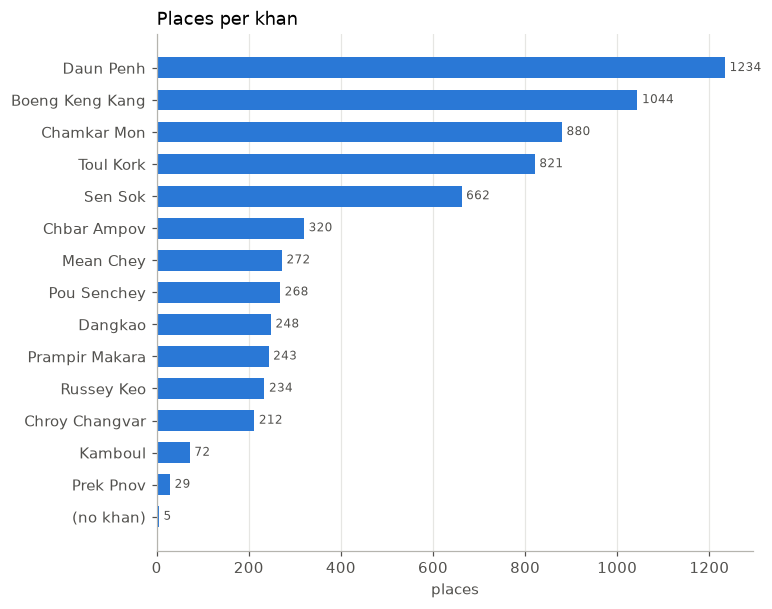

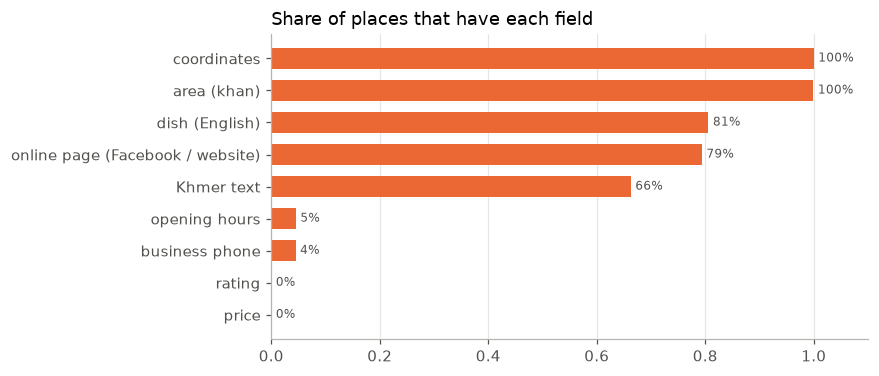

Only 0 place(s) have a price: no price chart yet. Add prices in the Google Sheet.


In [35]:
# Places per khan
per_area = df["area"].replace("", "(no khan)").value_counts().sort_values()
fig, ax = plt.subplots(figsize=(7, 0.34 * len(per_area) + 1))
bars = ax.barh(per_area.index, per_area.values, color=SERIES[0], height=0.65)
ax.bar_label(bars, padding=3, fontsize=8, color="#52514e")
ax.set_title("Places per khan", loc="left")
ax.set_xlabel("places")
ax.grid(axis="y", visible=False)
plt.show()

# How complete is each field?
comp = completeness.sort_values()
fig, ax = plt.subplots(figsize=(7, 3.6))
bars = ax.barh(comp.index, comp.values, color=SERIES[1], height=0.65)
ax.bar_label(bars, labels=[f"{v:.0%}" for v in comp.values], padding=3, fontsize=8, color="#52514e")
ax.set_xlim(0, 1.1)
ax.set_title("Share of places that have each field", loc="left")
ax.grid(axis="y", visible=False)
plt.show()

if df["price_usd"].notna().sum() >= 5:
    fig, ax = plt.subplots(figsize=(6, 3))
    ax.hist(df["price_usd"].dropna(), bins=8, color=SERIES[0], edgecolor="white", linewidth=2)
    ax.set_title("Price per dish (USD)", loc="left")
    ax.set_xlabel("USD")
    ax.set_ylabel("places")
    plt.show()
else:
    print(f"Only {int(df['price_usd'].notna().sum())} place(s) have a price: no price chart yet. Add prices in the Google Sheet.")

## 6. Save

**What:** write the clean table to **`data/restaurants.csv`** (the 18 columns + `page_url`; the first 18 work as a Google Sheet import).
The previous version is kept as `data/raw/restaurants_previous.csv`. Searchable text fields are lowercase; names and areas keep their case.
Next: open **`food_search.ipynb`**.

In [36]:
final = df[DATA_COLUMNS].copy()
assert final["id"].is_unique and not final["id"].isin(["", "nan"]).any(), "ids must be unique and not empty"
if CSV_PATH.exists():
    shutil.copy2(CSV_PATH, DATA_DIR / "raw" / "restaurants_previous.csv")
final.to_csv(CSV_PATH, index=False)
check = pd.read_csv(CSV_PATH, dtype=CSV_DTYPES)
assert len(check) == len(final) and list(check.columns) == DATA_COLUMNS
print(f"✅ {len(final)} places saved to data/restaurants.csv")
print("by source:", final["source"].value_counts().to_dict())

✅ 6544 places saved to data/restaurants.csv
by source: {'overture': 4725, 'openstreetmap': 1819}


## Summary

* One clean table with **18 columns + `page_url`**, built from OpenStreetMap, Overture Maps, the Google Sheet you maintain, and the Telegram sellers you imported.
* **`page_url`** is the seller's Facebook page or website: where a customer can look and order. It comes from open data (Overture, OpenStreetMap tags),
  never from scraping Facebook.
* **Limits** (see the quality report): the open data has no prices or ratings and little dish information, so the best results come
  from places you enrich in the sheet. A place's name and category are all we know about most Overture places.
* **Privacy:** no phone numbers or e-mails are taken from Overture, and none from Telegram; nothing is read from groups or private channels.
* **Credits:** © OpenStreetMap contributors (ODbL). Data from Meta, via the Overture Maps Foundation (CDLA Permissive 2.0).
* **Next:** `food_search.ipynb`.